# DEEP LEARNING - AIR QUALITY ROBUSTNESS ANALYSIS

## Research Question

**Do deep learning models remain reliable during extreme pollution episodes, or does their prediction performance degrade when AQI becomes severe?**

### Objective

This notebook evaluates the robustness of four deep learning architectures:

1. Multi-Layer Perceptron (MLP)
2. Recurrent Neural Network (RNN)
3. Gated Recurrent Unit (GRU)
4. Transformer

The models are evaluated for **US_AQI prediction** under:

- Overall air-quality conditions
- Extreme pollution conditions (`US_AQI >= 201`)

The main objective is to determine whether predictive performance degrades during extreme pollution episodes.

### Evaluation Metrics

The models will be evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [2]:
# ============================================================
#  IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Dense,
    SimpleRNN,
    GRU,
    MultiHeadAttention,
    LayerNormalization,
    Dropout,
    GlobalAveragePooling1D
)

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)


# ------------------------------------------------------------
# Version Check
# ------------------------------------------------------------

print("=" * 60)
print(" IMPORT LIBRARIES")
print("=" * 60)

print("\nTensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

print("\nAll libraries imported successfully.")

 IMPORT LIBRARIES

TensorFlow Version : 2.21.0
NumPy Version      : 2.4.3
Pandas Version     : 2.3.3

All libraries imported successfully.


In [3]:
# ============================================================
#  LOAD DATASET
# ============================================================

DATASET_PATH = (
    "../dataset/INDIA_AQI_COMPLETE_20251126.csv"
)

# Load dataset
df = pd.read_csv(DATASET_PATH)

print("=" * 60)
print(" DATASET LOADED")
print("=" * 60)

print("\nDataset Shape :", df.shape)

print(
    "\nDataset loaded successfully."
)

 DATASET LOADED

Dataset Shape : (842160, 71)

Dataset loaded successfully.


In [4]:
# ============================================================
#  DATASET VERIFICATION
# ============================================================

print("=" * 60)
print(" DATASET VERIFICATION")
print("=" * 60)

# 1. Dataset dimensions
print("\n1. Dataset Shape:")
print(df.shape)

# 2. Preview
print("\n2. First 5 Rows:")
display(df.head())

# 3. Required columns
required_columns = [
    "Datetime",
    "City",
    "US_AQI"
]

print("\n3. Required Column Verification:")

for column in required_columns:
    if column in df.columns:
        print(f"{column}: FOUND")
    else:
        print(f"{column}: MISSING")

# 4. Dataset data types
print("\n4. Datetime Data Type:")
print(df["Datetime"].dtype if "Datetime" in df.columns else "Missing")

print("\n5. Target Data Type:")
print(df["US_AQI"].dtype if "US_AQI" in df.columns else "Missing")

# 5. City count
if "City" in df.columns:
    print("\n6. Unique Cities:")
    print(df["City"].nunique())

# 6. Target missing values
if "US_AQI" in df.columns:
    print("\n7. Missing US_AQI Values:")
    print(df["US_AQI"].isna().sum())

# 7. Verification result
if all(column in df.columns for column in required_columns):
    print("\nDATASET VERIFICATION PASSED.")
else:
    raise ValueError(
        "Required columns are missing. Check the dataset."
    )

 DATASET VERIFICATION

1. Dataset Shape:
(842160, 71)

2. First 5 Rows:


,City,State,Latitude,Longitude,Datetime,Year,Month,Day,Hour,Day_of_Week,...,US_AQI_CO,EU_AQI,EU_AQI_PM25,EU_AQI_PM10,AQI_Category,PM25_Category_India,Temp_Inversion,Inversion_Strength_C,Festival_Period,Crop_Burning_Season
0,Agartala,Tripura,23.8315,91.2868,2022-08-05 00:00:00,2022,8,5,0,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
1,Agartala,Tripura,23.8315,91.2868,2022-08-05 01:00:00,2022,8,5,1,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
2,Agartala,Tripura,23.8315,91.2868,2022-08-05 02:00:00,2022,8,5,2,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
3,Agartala,Tripura,23.8315,91.2868,2022-08-05 03:00:00,2022,8,5,3,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
4,Agartala,Tripura,23.8315,91.2868,2022-08-05 04:00:00,2022,8,5,4,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0



3. Required Column Verification:
Datetime: FOUND
City: FOUND
US_AQI: FOUND

4. Datetime Data Type:
object

5. Target Data Type:
float64

6. Unique Cities:
29

7. Missing US_AQI Values:
145

DATASET VERIFICATION PASSED.


In [5]:

# ============================================================
#  TARGET & FEATURE DEFINITION
# ============================================================

TARGET = "US_AQI"

SEQUENCE_FEATURES = [
    "PM2_5_ugm3",
    "PM10_ugm3",
    "CO_ugm3",
    "NO2_ugm3",
    "SO2_ugm3",
    "O3_ugm3",
    "Dust_ugm3",
    "AOD",
    "Temp_2m_C",
    "Humidity_Percent",
    "Wind_Speed_10m_kmh",
    "Pressure_MSL_hPa",
    "Precipitation_mm",
    "Solar_Radiation_Wm2"
]

EXTREME_AQI_THRESHOLD = 201

print("=" * 60)
print(" TARGET & FEATURE DEFINITION")
print("=" * 60)

print("\nTarget Variable:", TARGET)
print("Number of Input Features:", len(SEQUENCE_FEATURES))

print("\nInput Features:")
for i, feature in enumerate(SEQUENCE_FEATURES, start=1):
    print(f"{i:02d}. {feature}")

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)

# Verify that all selected columns exist
missing_columns = [
    column
    for column in [TARGET, "Datetime", "City"] + SEQUENCE_FEATURES
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

print("\nAll required columns are available.")
print(" COMPLETED SUCCESSFULLY.")


 TARGET & FEATURE DEFINITION

Target Variable: US_AQI
Number of Input Features: 14

Input Features:
01. PM2_5_ugm3
02. PM10_ugm3
03. CO_ugm3
04. NO2_ugm3
05. SO2_ugm3
06. O3_ugm3
07. Dust_ugm3
08. AOD
09. Temp_2m_C
10. Humidity_Percent
11. Wind_Speed_10m_kmh
12. Pressure_MSL_hPa
13. Precipitation_mm
14. Solar_Radiation_Wm2

Extreme AQI Threshold: 201

All required columns are available.
 COMPLETED SUCCESSFULLY.



##  DATA LEAKAGE PREVENTION

Data leakage occurs when information that would not be available at prediction time influences model training or evaluation.

To reduce data leakage in this experiment:

1. `US_AQI` will be used only as the prediction target.
2. `City` and `Datetime` will be used to organize the time-series data, not as direct input features.
3. The selected input features will exclude `US_AQI` and other direct target-derived AQI columns.
4. Training and testing will follow a chronological strategy.
5. Feature scaling parameters will be learned from training-period data only.
6. Test-period observations will not be used to fit the models or preprocessing steps.

These precautions help provide a more realistic evaluation of future AQI prediction performance.


In [6]:

# ============================================================
#  MISSING TARGET HANDLING
# ============================================================

print("=" * 60)
print(" MISSING TARGET HANDLING")
print("=" * 60)

# Check missing target values
missing_target_count = df[TARGET].isna().sum()

print("\nTotal Dataset Rows :", len(df))
print("Missing US_AQI     :", missing_target_count)
print("Available Targets  :", df[TARGET].notna().sum())

# Check whether selected input features contain missing values
missing_feature_counts = df[SEQUENCE_FEATURES].isna().sum()

print("\nMissing Values in Input Features:")
print(missing_feature_counts[missing_feature_counts > 0])

# Preserve the original dataset.
# Rows with missing targets will not be used as prediction targets.
# They may still be useful as historical input observations.

df_model = df.copy()

print("\nOriginal dataset preserved in variable: df")
print("Working dataset created in variable: df_model")

print("\nNo rows have been deleted in this step.")
print("Missing-target observations will be excluded")
print("when prediction sequences are constructed.")

print("\n COMPLETED SUCCESSFULLY.")


 MISSING TARGET HANDLING

Total Dataset Rows : 842160
Missing US_AQI     : 145
Available Targets  : 842015

Missing Values in Input Features:
Series([], dtype: int64)

Original dataset preserved in variable: df
Working dataset created in variable: df_model

No rows have been deleted in this step.
Missing-target observations will be excluded
when prediction sequences are constructed.

 COMPLETED SUCCESSFULLY.


In [7]:

# ============================================================
#  CATEGORICAL ENCODING & DATETIME PREPARATION
# ============================================================

print("=" * 60)
print(" CATEGORICAL ENCODING & DATETIME PREPARATION")
print("=" * 60)

# 1. Convert Datetime to pandas datetime format
df_model["Datetime"] = pd.to_datetime(
    df_model["Datetime"],
    errors="raise"
)

# 2. Verify that all selected input features are numeric
non_numeric_features = [
    feature
    for feature in SEQUENCE_FEATURES
    if not pd.api.types.is_numeric_dtype(df_model[feature])
]

if non_numeric_features:
    raise TypeError(
        f"Non-numeric input features found: {non_numeric_features}"
    )

# 3. Keep City as a grouping identifier, not a model input
print("\nCity Encoding:")
print("City will be used for grouping, not as a model feature.")
print("No categorical encoding is required for the selected inputs.")

# 4. Sort observations chronologically within each city
df_model = df_model.sort_values(
    ["City", "Datetime"]
).reset_index(drop=True)

# 5. Check duplicate city-timestamp combinations
duplicate_count = df_model.duplicated(
    subset=["City", "Datetime"]
).sum()

# 6. Check time gaps between consecutive observations
time_differences = (
    df_model.groupby("City")["Datetime"].diff()
)

gap_count = (
    time_differences.notna()
    & (time_differences != pd.Timedelta(hours=1))
).sum()

print("\nDatetime Data Type:", df_model["Datetime"].dtype)
print("Number of Cities:", df_model["City"].nunique())
print("Duplicate City-Timestamp Rows:", duplicate_count)
print("Non-hourly Consecutive Time Differences:", gap_count)

print("\nSorted Dataset Shape:", df_model.shape)

if duplicate_count > 0:
    print("\nWARNING: Duplicate city-timestamp records require investigation.")
else:
    print("\nNo duplicate city-timestamp records found.")

if gap_count > 0:
    print("WARNING: Time gaps or irregular intervals were detected.")
    print("Sequence construction must account for these intervals.")
else:
    print("All consecutive observations are hourly within each city.")

print("\ COMPLETED.")


 CATEGORICAL ENCODING & DATETIME PREPARATION

City Encoding:
City will be used for grouping, not as a model feature.
No categorical encoding is required for the selected inputs.

Datetime Data Type: datetime64[ns]
Number of Cities: 29
Duplicate City-Timestamp Rows: 0
Non-hourly Consecutive Time Differences: 0

Sorted Dataset Shape: (842160, 71)

No duplicate city-timestamp records found.
All consecutive observations are hourly within each city.
\ COMPLETED.



##  CHRONOLOGICAL TRAIN-TEST SPLIT

A chronological evaluation strategy will be used for this time-series forecasting experiment.

- Training period: the earlier 80% of the timeline.
- Testing period: the later 20% of the timeline.
- The temporal cutoff will be based on timestamps rather than random row selection.
- The same temporal cutoff will be applied consistently across all cities.
- Test-period observations will remain separate from model fitting and preprocessing.

This approach evaluates how well the models generalize to later observations.


In [8]:

# ============================================================
#  DEFINE CHRONOLOGICAL TRAIN-TEST CUTOFF
# ============================================================

print("=" * 60)
print(" CHRONOLOGICAL TRAIN-TEST CUTOFF")
print("=" * 60)

# Sort unique timestamps across the complete dataset
unique_timestamps = np.sort(
    df_model["Datetime"].unique()
)

# Use the first 80% of timestamps for training
split_index = int(len(unique_timestamps) * 0.80)

# Ensure both periods contain timestamps
if split_index <= 0 or split_index >= len(unique_timestamps):
    raise ValueError("Invalid chronological split index.")

TRAIN_END_TIME = pd.Timestamp(
    unique_timestamps[split_index - 1]
)

TEST_START_TIME = pd.Timestamp(
    unique_timestamps[split_index]
)

# Assign rows according to timestamp
train_mask = df_model["Datetime"] <= TRAIN_END_TIME
test_mask = df_model["Datetime"] >= TEST_START_TIME

train_rows = df_model.loc[train_mask]
test_rows = df_model.loc[test_mask]

print("\nTotal Unique Timestamps:", len(unique_timestamps))
print("Training Cutoff:", TRAIN_END_TIME)
print("Testing Starts :", TEST_START_TIME)

print("\nTraining Rows:", len(train_rows))
print("Testing Rows :", len(test_rows))

print("\nTraining Period:")
print(train_rows["Datetime"].min(), "to", train_rows["Datetime"].max())

print("\nTesting Period:")
print(test_rows["Datetime"].min(), "to", test_rows["Datetime"].max())

print("\nTraining Percentage:", round(len(train_rows) / len(df_model) * 100, 2), "%")
print("Testing Percentage :", round(len(test_rows) / len(df_model) * 100, 2), "%")

# Verify chronological separation
assert train_rows["Datetime"].max() < test_rows["Datetime"].min()

print("\nChronological separation verified.")
print(" COMPLETED SUCCESSFULLY.")


 CHRONOLOGICAL TRAIN-TEST CUTOFF

Total Unique Timestamps: 29040
Training Cutoff: 2025-03-29 23:00:00
Testing Starts : 2025-03-30 00:00:00

Training Rows: 673728
Testing Rows : 168432

Training Period:
2022-08-05 00:00:00 to 2025-03-29 23:00:00

Testing Period:
2025-03-30 00:00:00 to 2025-11-26 23:00:00

Training Percentage: 80.0 %
Testing Percentage : 20.0 %

Chronological separation verified.
 COMPLETED SUCCESSFULLY.


In [9]:

# ============================================================
#  LEAKAGE-SAFE FEATURE SCALING
# ============================================================

print("=" * 60)
print(" LEAKAGE-SAFE FEATURE SCALING")
print("=" * 60)

# Create a dedicated scaler
feature_scaler = StandardScaler()

# Fit the scaler using training-period rows ONLY
training_feature_mask = (
    df_model["Datetime"] <= TRAIN_END_TIME
)

feature_scaler.fit(
    df_model.loc[training_feature_mask, SEQUENCE_FEATURES]
)

# Transform features for both training and testing periods
# Test data is transformed, but never used to fit the scaler.
df_scaled = df_model.copy()

df_scaled.loc[:, SEQUENCE_FEATURES] = feature_scaler.transform(
    df_model[SEQUENCE_FEATURES]
)

print("\nTraining cutoff:", TRAIN_END_TIME)
print("Training rows used to fit scaler:", training_feature_mask.sum())
print("Test rows used to fit scaler: 0")

print("\nScaled Dataset Shape:", df_scaled.shape)

print("\nExample: Original Feature Values")
display(df_model[SEQUENCE_FEATURES].head(3))

print("\nExample: Scaled Feature Values")
display(df_scaled[SEQUENCE_FEATURES].head(3))

# Verify that scaling parameters were fitted only on training data
assert feature_scaler.n_samples_seen_ == training_feature_mask.sum()

# Verify no missing values were introduced
assert df_scaled[SEQUENCE_FEATURES].isna().sum().sum() == 0

print("\nScaler fitted exclusively on training-period features.")
print("No missing values introduced by scaling.")
print(" COMPLETED SUCCESSFULLY.")


 LEAKAGE-SAFE FEATURE SCALING

Training cutoff: 2025-03-29 23:00:00
Training rows used to fit scaler: 673728
Test rows used to fit scaler: 0

Scaled Dataset Shape: (842160, 71)

Example: Original Feature Values


,PM2_5_ugm3,PM10_ugm3,CO_ugm3,NO2_ugm3,SO2_ugm3,O3_ugm3,Dust_ugm3,AOD,Temp_2m_C,Humidity_Percent,Wind_Speed_10m_kmh,Pressure_MSL_hPa,Precipitation_mm,Solar_Radiation_Wm2
0,14.8,21.5,197.0,21.8,2.7,32.0,0.0,0.14,26.7,91,5.4,1004.4,0.0,0.0
1,15.7,22.8,196.0,18.5,3.0,33.0,0.0,0.14,26.4,93,4.5,1003.9,0.0,0.0
2,16.3,23.5,196.0,15.1,3.3,34.0,0.0,0.15,26.1,95,3.8,1003.5,0.0,0.0



Example: Scaled Feature Values


,PM2_5_ugm3,PM10_ugm3,CO_ugm3,NO2_ugm3,SO2_ugm3,O3_ugm3,Dust_ugm3,AOD,Temp_2m_C,Humidity_Percent,Wind_Speed_10m_kmh,Pressure_MSL_hPa,Precipitation_mm,Solar_Radiation_Wm2
0,-0.666509,-0.542575,-0.581880,0.226499,-0.539992,-1.037706,-0.17887,-1.027739,0.508451,0.952197,-0.552519,-1.020244,-0.204678,-0.735772
1,-0.637986,-0.522015,-0.584028,0.076992,-0.526606,-1.016191,-0.17887,-1.027739,0.465922,1.045631,-0.728968,-1.108979,-0.204678,-0.735772
2,-0.618970,-0.510943,-0.584028,-0.077045,-0.513220,-0.994676,-0.17887,-0.995847,0.423392,1.139064,-0.866206,-1.179967,-0.204678,-0.735772



Scaler fitted exclusively on training-period features.
No missing values introduced by scaling.
 COMPLETED SUCCESSFULLY.


In [10]:

# ============================================================
#  TIME-SERIES SEQUENCE CREATION
# ============================================================

LOOKBACK = 24

X_sequences = []
y_sequences = []
sequence_cities = []
sequence_target_times = []

for city, city_df in df_scaled.groupby("City", sort=False):

    city_df = city_df.sort_values("Datetime").reset_index(drop=True)

    # Keep the original, unscaled AQI target
    original_city_df = df_model[
        df_model["City"] == city
    ].sort_values("Datetime").reset_index(drop=True)

    # Confirm feature and target rows remain aligned
    assert np.array_equal(
        city_df["Datetime"].to_numpy(),
        original_city_df["Datetime"].to_numpy()
    )

    feature_values = city_df[SEQUENCE_FEATURES].to_numpy(
        dtype=np.float32
    )

    target_values = original_city_df[TARGET].to_numpy(
        dtype=np.float32
    )

    timestamps = city_df["Datetime"].to_numpy()

    for i in range(LOOKBACK, len(city_df)):

        # Exclude rows whose AQI target is missing
        if not np.isfinite(target_values[i]):
            continue

        # Use the preceding 24 hours only
        X_sequences.append(
            feature_values[i - LOOKBACK:i]
        )

        y_sequences.append(target_values[i])
        sequence_cities.append(city)
        sequence_target_times.append(timestamps[i])

X_sequences = np.asarray(X_sequences, dtype=np.float32)
y_sequences = np.asarray(y_sequences, dtype=np.float32)
sequence_cities = np.asarray(sequence_cities)
sequence_target_times = pd.to_datetime(sequence_target_times)

print("=" * 60)
print(" TIME-SERIES SEQUENCE CREATION")
print("=" * 60)

print("\nLookback Window:", LOOKBACK, "hours")
print("Number of Input Features:", len(SEQUENCE_FEATURES))
print("X Sequences Shape:", X_sequences.shape)
print("y Sequences Shape:", y_sequences.shape)
print("Number of Cities:", len(np.unique(sequence_cities)))

print("\nMissing Values in X:", np.isnan(X_sequences).sum())
print("Missing Values in y:", np.isnan(y_sequences).sum())

print("\nFirst Sequence City:", sequence_cities[0])
print("First Target Timestamp:", sequence_target_times[0])
print("First Target US_AQI:", y_sequences[0])

assert X_sequences.ndim == 3
assert X_sequences.shape[1] == LOOKBACK
assert X_sequences.shape[2] == len(SEQUENCE_FEATURES)
assert len(X_sequences) == len(y_sequences)
assert np.isfinite(X_sequences).all()
assert np.isfinite(y_sequences).all()

print("\nSequence checks passed.")
print(" COMPLETED SUCCESSFULLY.")


 TIME-SERIES SEQUENCE CREATION

Lookback Window: 24 hours
Number of Input Features: 14
X Sequences Shape: (841464, 24, 14)
y Sequences Shape: (841464,)
Number of Cities: 29

Missing Values in X: 0
Missing Values in y: 0

First Sequence City: Agartala
First Target Timestamp: 2022-08-06 00:00:00
First Target US_AQI: 54.0

Sequence checks passed.
 COMPLETED SUCCESSFULLY.


In [11]:

# ============================================================
#  SEQUENCE CHRONOLOGICAL SPLIT & SCALING
# ============================================================

print("=" * 60)
print(" SEQUENCE CHRONOLOGICAL SPLIT & SCALING")
print("=" * 60)

# Identify samples by their target timestamps.
train_sequence_mask = (
    sequence_target_times <= TRAIN_END_TIME
)

test_sequence_mask = (
    sequence_target_times >= TEST_START_TIME
)

# Split sequences, targets, city identifiers and timestamps.
X_train_seq = X_sequences[train_sequence_mask]
y_train_seq = y_sequences[train_sequence_mask]

X_test_seq = X_sequences[test_sequence_mask]
y_test_seq = y_sequences[test_sequence_mask]

train_cities = sequence_cities[train_sequence_mask]
test_cities = sequence_cities[test_sequence_mask]

train_target_times = sequence_target_times[train_sequence_mask]
test_target_times = sequence_target_times[test_sequence_mask]

# Confirm that every sequence belongs to exactly one period.
assert np.all(train_sequence_mask | test_sequence_mask)
assert not np.any(train_sequence_mask & test_sequence_mask)

# Confirm chronological separation.
assert train_target_times.max() <= TRAIN_END_TIME
assert test_target_times.min() >= TEST_START_TIME
assert train_target_times.max() < test_target_times.min()

# Confirm there are no missing values.
assert np.isfinite(X_train_seq).all()
assert np.isfinite(X_test_seq).all()
assert np.isfinite(y_train_seq).all()
assert np.isfinite(y_test_seq).all()

print("\nTraining Cutoff:", TRAIN_END_TIME)
print("Testing Starts :", TEST_START_TIME)

print("\nTraining Sequence Shape:", X_train_seq.shape)
print("Training Target Shape  :", y_train_seq.shape)

print("\nTesting Sequence Shape :", X_test_seq.shape)
print("Testing Target Shape   :", y_test_seq.shape)

print("\nTraining Cities:", len(np.unique(train_cities)))
print("Testing Cities :", len(np.unique(test_cities)))

print("\nTraining Target Period:")
print(train_target_times.min(), "to", train_target_times.max())

print("\nTesting Target Period:")
print(test_target_times.min(), "to", test_target_times.max())

print("\nTraining Samples:", len(y_train_seq))
print("Testing Samples :", len(y_test_seq))

print("\nFeature Scaling:")
print("Scaler was fitted on training-period rows only in STEP 10.")
print("No additional scaler fitting was performed in STEP 12.")

print("\nMissing Values:")
print("X_train:", np.isnan(X_train_seq).sum())
print("X_test :", np.isnan(X_test_seq).sum())
print("y_train:", np.isnan(y_train_seq).sum())
print("y_test :", np.isnan(y_test_seq).sum())

print("\nChronological split and validation checks passed.")
print(" COMPLETED SUCCESSFULLY.")


 SEQUENCE CHRONOLOGICAL SPLIT & SCALING

Training Cutoff: 2025-03-29 23:00:00
Testing Starts : 2025-03-30 00:00:00

Training Sequence Shape: (673032, 24, 14)
Training Target Shape  : (673032,)

Testing Sequence Shape : (168432, 24, 14)
Testing Target Shape   : (168432,)

Training Cities: 29
Testing Cities : 29

Training Target Period:
2022-08-06 00:00:00 to 2025-03-29 23:00:00

Testing Target Period:
2025-03-30 00:00:00 to 2025-11-26 23:00:00

Training Samples: 673032
Testing Samples : 168432

Feature Scaling:
Scaler was fitted on training-period rows only in STEP 10.
No additional scaler fitting was performed in STEP 12.

Missing Values:
X_train: 0
X_test : 0
y_train: 0
y_test : 0

Chronological split and validation checks passed.
 COMPLETED SUCCESSFULLY.


In [12]:

# ============================================================
#  COMMON TRAINING CONFIGURATION
# ============================================================

print("=" * 60)
print(" COMMON TRAINING CONFIGURATION")
print("=" * 60)

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Common training settings
BATCH_SIZE = 512
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
VALIDATION_SPLIT = 0.10
LEARNING_RATE = 0.001

# Common loss and metric names
LOSS_FUNCTION = "mse"
EVALUATION_METRIC = "mae"

# Common optimizer factory
def create_optimizer():
    return keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

# Common early stopping factory
def create_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        mode="min",
        verbose=1
    )

print("\nRandom Seed:", RANDOM_SEED)
print("Batch Size:", BATCH_SIZE)
print("Maximum Epochs:", MAX_EPOCHS)
print("Early Stopping Patience:", EARLY_STOPPING_PATIENCE)
print("Validation Split:", VALIDATION_SPLIT)
print("Learning Rate:", LEARNING_RATE)
print("Loss Function:", LOSS_FUNCTION)
print("Evaluation Metric:", EVALUATION_METRIC)

print("\nAll four models will use the same training settings.")
print("Model parameter equality will be checked separately.")

print("\n COMPLETED SUCCESSFULLY.")


 COMMON TRAINING CONFIGURATION

Random Seed: 42
Batch Size: 512
Maximum Epochs: 20
Early Stopping Patience: 5
Validation Split: 0.1
Learning Rate: 0.001
Loss Function: mse
Evaluation Metric: mae

All four models will use the same training settings.
Model parameter equality will be checked separately.

 COMPLETED SUCCESSFULLY.


#  MLP (Multi-Layer Perceptron)

In [13]:

# ============================================================
#  BUILD MLP
# ============================================================
print("=" * 60)
print(" BUILD MLP ")
print("=" * 60)

mlp_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, len(SEQUENCE_FEATURES))),
    layers.Flatten(),
    layers.Dense(160, activation="relu"),
    layers.Dense(37, activation="relu"),
    layers.Dense(1, activation="linear")
], name="MLP_AQI_Model")

mlp_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

mlp_model.summary()

mlp_total_params = mlp_model.count_params()

mlp_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in mlp_model.trainable_weights
)

mlp_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in mlp_model.non_trainable_weights
)

print("\nMLP Parameter Counts:")
print("Total Parameters:", mlp_total_params)
print("Trainable Parameters:", mlp_trainable_params)
print("Non-Trainable Parameters:", mlp_non_trainable_params)

assert mlp_total_params == 59915
assert mlp_trainable_params == 59915
assert mlp_non_trainable_params == 0

TARGET_PARAMETER_COUNT = mlp_total_params

print("\nTarget Parameter Budget:", TARGET_PARAMETER_COUNT)
print("STEP  COMPLETED SUCCESSFULLY.")


 BUILD MLP 


Model: "MLP_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 336)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 160)                 │          53,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 37)                  │           5,957 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              38 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 59,915 (234.04 KB)

 Trainable params: 59,915 (234.04 KB)

 Non-trainable params: 0 (0.00 B)


MLP Parameter Counts:
Total Parameters: 59915
Trainable Parameters: 59915
Non-Trainable Parameters: 0

Target Parameter Budget: 59915
STEP  COMPLETED SUCCESSFULLY.


In [14]:

# ============================================================
#  TRAIN MLP
# ============================================================

print("=" * 60)
print(" TRAIN MLP")
print("=" * 60)

# Verify the new model has the intended parameter count.
assert mlp_model.count_params() == TARGET_PARAMETER_COUNT

# Train with the common configuration.
mlp_early_stopping = create_early_stopping()

mlp_history = mlp_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[mlp_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nMLP Training Completed.")
print("Total Parameters:", mlp_model.count_params())
print("Epochs Completed:", len(mlp_history.history["loss"]))
print("Best Validation Loss:", min(mlp_history.history["val_loss"]))
print("Final Training Loss:", mlp_history.history["loss"][-1])
print("Final Validation Loss:", mlp_history.history["val_loss"][-1])

print("\n COMPLETED SUCCESSFULLY.")



 TRAIN MLP
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - loss: 1182.2925 - mae: 20.9799 - val_loss: 311.3124 - val_mae: 13.1757
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 528.2227 - mae: 14.5281 - val_loss: 406.3107 - val_mae: 13.9891
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 203.2796 - mae: 10.4110 - val_loss: 272.6493 - val_mae: 11.8119
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 322.5285 - mae: 11.9326 - val_loss: 271.2316 - val_mae: 11.5618
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 213.4006 - mae: 10.0975 - val_loss: 188.6485 - val_mae: 10.1927
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 459.0468 - mae: 12.7296 - val_loss: 280.8214 - val_mae: 11.7238
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 140.8332 - mae: 8.4139 - val_loss: 179.9652 - val_mae: 9.5973
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 116.3887 - mae: 7.5788 - val_loss: 1

In [15]:

# ============================================================
#  EVALUATE MLP
# ============================================================

print("=" * 60)
print(" EVALUATE MLP")
print("=" * 60)

# Confirm that the updated MLP is being evaluated.
assert mlp_model.count_params() == TARGET_PARAMETER_COUNT

# Predict on the held-out test set.
mlp_test_predictions = mlp_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

# Calculate metrics in the original US_AQI scale.
mlp_test_mae = mean_absolute_error(
    y_test_seq,
    mlp_test_predictions
)

mlp_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        mlp_test_predictions
    )
)

mlp_test_r2 = r2_score(
    y_test_seq,
    mlp_test_predictions
)

print("\nUPDATED MLP TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", mlp_model.count_params())
print(f"MAE  : {mlp_test_mae:.4f}")
print(f"RMSE : {mlp_test_rmse:.4f}")
print(f"R²   : {mlp_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(mlp_test_predictions))

assert len(y_test_seq) == len(mlp_test_predictions)
assert np.isfinite(mlp_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE MLP
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

UPDATED MLP TEST PERFORMANCE
---------------------------------------------
Total Parameters: 59915
MAE  : 7.5443
RMSE : 17.0179
R²   : 0.9771

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [16]:

# ============================================================
#  MLP EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" MLP EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

mlp_extreme_mask = y_test_seq >= EXTREME_AQI_THRESHOLD

y_mlp_extreme = y_test_seq[mlp_extreme_mask]
pred_mlp_extreme = mlp_test_predictions[mlp_extreme_mask]

mlp_extreme_count = len(y_mlp_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", mlp_extreme_count)

if mlp_extreme_count >= 2:
    mlp_extreme_mae = mean_absolute_error(
        y_mlp_extreme, pred_mlp_extreme
    )
    mlp_extreme_rmse = np.sqrt(
        mean_squared_error(y_mlp_extreme, pred_mlp_extreme)
    )
    mlp_extreme_r2 = r2_score(
        y_mlp_extreme, pred_mlp_extreme
    )

    print("\nUPDATED MLP EXTREME PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {mlp_extreme_mae:.4f}")
    print(f"Extreme RMSE : {mlp_extreme_rmse:.4f}")
    print(f"Extreme R²   : {mlp_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{mlp_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")



 MLP EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

UPDATED MLP EXTREME PERFORMANCE
---------------------------------------------
Extreme MAE  : 62.6798
Extreme RMSE : 88.8446
Extreme R²   : 0.9593
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


# Simple Recurrent Neural Network (RNN)

In [17]:

# ============================================================
#  BUILD RNN 
# ============================================================

print("=" * 60)
print(" BUILD RNN")
print("=" * 60)

TARGET_PARAMETER_COUNT = mlp_model.count_params()
INPUT_FEATURES = len(SEQUENCE_FEATURES)

# Search for an exact parameter match:
# SimpleRNN(n) -> Dense(p) -> Dense(1)
#
# Total parameters:
# n * (INPUT_FEATURES + n + 1) + p * (n + 1) + (p + 1)

matching_config = None

for n in range(1, 300):
    rnn_params = n * (INPUT_FEATURES + n + 1)

    for p in range(1, 20000):
        total_params = rnn_params + p * (n + 1) + (p + 1)

        if total_params == TARGET_PARAMETER_COUNT:
            matching_config = (n, p)
            break

    if matching_config is not None:
        break

if matching_config is None:
    raise ValueError("Exact RNN parameter match not found.")

rnn_units, dense_units = matching_config

rnn_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, INPUT_FEATURES)),
    layers.SimpleRNN(rnn_units, activation="tanh"),
    layers.Dense(dense_units, activation="relu"),
    layers.Dense(1, activation="linear")
], name="RNN_AQI_Model")

rnn_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

rnn_total_params = rnn_model.count_params()

rnn_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in rnn_model.trainable_weights
)

rnn_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in rnn_model.non_trainable_weights
)

rnn_model.summary()

print("\nRNN Parameter Counts:")
print("Total Parameters:", rnn_total_params)
print("Trainable Parameters:", rnn_trainable_params)
print("Non-Trainable Parameters:", rnn_non_trainable_params)

assert rnn_total_params == mlp_total_params
assert rnn_trainable_params == mlp_trainable_params
assert rnn_non_trainable_params == mlp_non_trainable_params

print("\nRNN and MLP parameter counts match exactly.")
print(" COMPLETED SUCCESSFULLY.")


 BUILD RNN


Model: "RNN_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 1)                   │              16 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 19966)               │          39,932 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │          19,967 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 59,915 (234.04 KB)

 Trainable params: 59,915 (234.04 KB)

 Non-trainable params: 0 (0.00 B)


RNN Parameter Counts:
Total Parameters: 59915
Trainable Parameters: 59915
Non-Trainable Parameters: 0

RNN and MLP parameter counts match exactly.
 COMPLETED SUCCESSFULLY.


In [18]:

# ============================================================
#  TRAIN RNN
# ============================================================


print("=" * 60)
print(" TRAIN RNN")
print("=" * 60)

# Verify parameter equality before training.
assert rnn_model.count_params() == mlp_model.count_params()
assert rnn_trainable_params == mlp_trainable_params
assert rnn_non_trainable_params == mlp_non_trainable_params

rnn_early_stopping = create_early_stopping()

rnn_history = rnn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[rnn_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nUpdated RNN Training Completed.")
print("Total Parameters:", rnn_model.count_params())
print("Epochs Completed:", len(rnn_history.history["loss"]))
print("Best Validation Loss:", min(rnn_history.history["val_loss"]))
print("Final Training Loss:", rnn_history.history["loss"][-1])
print("Final Validation Loss:", rnn_history.history["val_loss"][-1])

print("\n COMPLETED SUCCESSFULLY.")



 TRAIN RNN
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 49s 39ms/step - loss: 2767.1194 - mae: 32.6033 - val_loss: 928.7210 - val_mae: 23.9419
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 60s 50ms/step - loss: 1744.5209 - mae: 22.4159 - val_loss: 642.8376 - val_mae: 19.3969
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 61s 52ms/step - loss: 1539.7808 - mae: 19.1055 - val_loss: 516.8688 - val_mae: 17.7060
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 70s 42ms/step - loss: 1403.6692 - mae: 17.1884 - val_loss: 449.4658 - val_mae: 16.7247
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 78s 38ms/step - loss: 1337.0226 - mae: 16.5274 - val_loss: 443.7368 - val_mae: 16.4962
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 85s 40ms/step - loss: 1315.7961 - mae: 16.6017 - val_loss: 423.6652 - val_mae: 15.9059
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 61s 51ms/step - loss: 1309.4668 - mae: 16.7975 - val_loss: 421.3843 - val_mae: 15.8081
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 59s 50ms/step - loss: 1306.6049 - mae: 16.95

In [19]:

# ============================================================
#  EVALUATE RNN
# ============================================================

print("=" * 60)
print(" EVALUATE RNN")
print("=" * 60)

# Verify equal parameter counts before evaluation.
assert rnn_model.count_params() == mlp_model.count_params()

rnn_test_predictions = rnn_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

rnn_test_mae = mean_absolute_error(
    y_test_seq,
    rnn_test_predictions
)

rnn_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        rnn_test_predictions
    )
)

rnn_test_r2 = r2_score(
    y_test_seq,
    rnn_test_predictions
)

print("\nUPDATED RNN TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", rnn_model.count_params())
print(f"MAE  : {rnn_test_mae:.4f}")
print(f"RMSE : {rnn_test_rmse:.4f}")
print(f"R²   : {rnn_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(rnn_test_predictions))

assert len(y_test_seq) == len(rnn_test_predictions)
assert np.isfinite(rnn_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE RNN
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step

UPDATED RNN TEST PERFORMANCE
---------------------------------------------
Total Parameters: 59915
MAE  : 26.7387
RMSE : 94.5771
R²   : 0.2926

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [20]:

# ============================================================
#  RNN EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" RNN EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

rnn_extreme_mask = y_test_seq >= EXTREME_AQI_THRESHOLD

y_rnn_extreme = y_test_seq[rnn_extreme_mask]
pred_rnn_extreme = rnn_test_predictions[rnn_extreme_mask]

rnn_extreme_count = len(y_rnn_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", rnn_extreme_count)

if rnn_extreme_count >= 2:
    rnn_extreme_mae = mean_absolute_error(
        y_rnn_extreme, pred_rnn_extreme
    )

    rnn_extreme_rmse = np.sqrt(
        mean_squared_error(y_rnn_extreme, pred_rnn_extreme)
    )

    rnn_extreme_r2 = r2_score(
        y_rnn_extreme, pred_rnn_extreme
    )

    print("\nRNN EXTREME POLLUTION PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {rnn_extreme_mae:.4f}")
    print(f"Extreme RMSE : {rnn_extreme_rmse:.4f}")
    print(f"Extreme R²   : {rnn_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{rnn_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")


 RNN EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

RNN EXTREME POLLUTION PERFORMANCE
---------------------------------------------
Extreme MAE  : 384.5475
Extreme RMSE : 573.4059
Extreme R²   : -0.6933
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


# Gated Recurrent Unit (GRU)

In [21]:

# ============================================================
#  BUILD GRU 
# ============================================================

print("=" * 60)
print(" BUILD GRU")
print("=" * 60)

TARGET_PARAMETER_COUNT = mlp_model.count_params()
INPUT_FEATURES = len(SEQUENCE_FEATURES)

# Search for a GRU architecture with an exact parameter match.
# Architecture:
# GRU(units) -> Dense(hidden_units) -> Dense(1)

matching_config = None

for gru_units in range(2, 200):
    gru_params = 3 * gru_units * (
        INPUT_FEATURES + gru_units + 2
    )

    for hidden_units in range(1, 20000):
        dense_params = gru_units * hidden_units + hidden_units
        output_params = hidden_units + 1

        total_params = gru_params + dense_params + output_params

        if total_params == TARGET_PARAMETER_COUNT:
            matching_config = (gru_units, hidden_units)
            break

    if matching_config is not None:
        break

if matching_config is None:
    raise ValueError(
        "No exact GRU parameter match found. "
        "Do not train until the architecture is resolved."
    )

gru_units, gru_hidden_units = matching_config

gru_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, INPUT_FEATURES)),
    layers.GRU(gru_units, activation="tanh"),
    layers.Dense(gru_hidden_units, activation="relu"),
    layers.Dense(1, activation="linear")
], name="GRU_AQI_Model")

gru_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

gru_model.summary()

gru_total_params = gru_model.count_params()

gru_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in gru_model.trainable_weights
)

gru_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in gru_model.non_trainable_weights
)

print("\nGRU Parameter Counts:")
print("GRU Units:", gru_units)
print("Dense Hidden Units:", gru_hidden_units)
print("Total Parameters:", gru_total_params)
print("Trainable Parameters:", gru_trainable_params)
print("Non-Trainable Parameters:", gru_non_trainable_params)

assert gru_total_params == mlp_total_params
assert gru_trainable_params == mlp_trainable_params
assert gru_non_trainable_params == mlp_non_trainable_params

print("\nGRU parameter counts match MLP exactly.")
print(" COMPLETED SUCCESSFULLY.")


 BUILD GRU


Model: "GRU_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 129)                 │          56,115 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 29)                  │           3,770 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1)                   │              30 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 59,915 (234.04 KB)

 Trainable params: 59,915 (234.04 KB)

 Non-trainable params: 0 (0.00 B)


GRU Parameter Counts:
GRU Units: 129
Dense Hidden Units: 29
Total Parameters: 59915
Trainable Parameters: 59915
Non-Trainable Parameters: 0

GRU parameter counts match MLP exactly.
 COMPLETED SUCCESSFULLY.


In [22]:

# ============================================================
#  TRAIN GRU
# ============================================================

print("=" * 60)
print(" TRAIN GRU")
print("=" * 60)

# Verify equal parameter counts before training.
assert gru_model.count_params() == mlp_model.count_params()
assert gru_trainable_params == mlp_trainable_params
assert gru_non_trainable_params == mlp_non_trainable_params

gru_early_stopping = create_early_stopping()

gru_history = gru_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[gru_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nGRU Training Completed.")
print("Total Parameters:", gru_model.count_params())
print("Epochs Completed:", len(gru_history.history["loss"]))
print("Best Validation Loss:", min(gru_history.history["val_loss"]))
print("Final Training Loss:", gru_history.history["loss"][-1])
print("Final Validation Loss:", gru_history.history["val_loss"][-1])

print("\n COMPLETED SUCCESSFULLY.")


 TRAIN GRU
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 285s 238ms/step - loss: 2224.3337 - mae: 23.1386 - val_loss: 151.9806 - val_mae: 8.9242
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 253s 214ms/step - loss: 994.5146 - mae: 8.6121 - val_loss: 116.0267 - val_mae: 8.0413
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 292s 239ms/step - loss: 867.9951 - mae: 7.3150 - val_loss: 75.9296 - val_mae: 6.5207
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 306s 225ms/step - loss: 776.2405 - mae: 6.5665 - val_loss: 62.4128 - val_mae: 6.0989
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 332s 233ms/step - loss: 695.2144 - mae: 5.9027 - val_loss: 48.1698 - val_mae: 5.2855
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 299s 213ms/step - loss: 610.7998 - mae: 5.3288 - val_loss: 54.7685 - val_mae: 5.9653
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 267s 225ms/step - loss: 551.4980 - mae: 5.2266 - val_loss: 47.4024 - val_mae: 5.5039
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 317s 221ms/step - loss: 482.7049 - mae: 4.7344 - val_l

In [23]:

# ============================================================
#  EVALUATE GRU
# ============================================================

print("=" * 60)
print(" EVALUATE GRU")
print("=" * 60)

# Verify that the GRU has the common parameter budget.
assert gru_model.count_params() == mlp_model.count_params()

gru_test_predictions = gru_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

gru_test_mae = mean_absolute_error(
    y_test_seq,
    gru_test_predictions
)

gru_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        gru_test_predictions
    )
)

gru_test_r2 = r2_score(
    y_test_seq,
    gru_test_predictions
)

print("\nGRU TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", gru_model.count_params())
print(f"MAE  : {gru_test_mae:.4f}")
print(f"RMSE : {gru_test_rmse:.4f}")
print(f"R²   : {gru_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(gru_test_predictions))

assert len(y_test_seq) == len(gru_test_predictions)
assert np.isfinite(gru_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE GRU
329/329 ━━━━━━━━━━━━━━━━━━━━ 27s 81ms/step

GRU TEST PERFORMANCE
---------------------------------------------
Total Parameters: 59915
MAE  : 8.6067
RMSE : 52.6969
R²   : 0.7804

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [24]:

# ============================================================
#  GRU EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" GRU EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

gru_extreme_mask = y_test_seq >= EXTREME_AQI_THRESHOLD

y_gru_extreme = y_test_seq[gru_extreme_mask]
pred_gru_extreme = gru_test_predictions[gru_extreme_mask]

gru_extreme_count = len(y_gru_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", gru_extreme_count)

if gru_extreme_count >= 2:
    gru_extreme_mae = mean_absolute_error(
        y_gru_extreme,
        pred_gru_extreme
    )

    gru_extreme_rmse = np.sqrt(
        mean_squared_error(
            y_gru_extreme,
            pred_gru_extreme
        )
    )

    gru_extreme_r2 = r2_score(
        y_gru_extreme,
        pred_gru_extreme
    )

    print("\nGRU EXTREME POLLUTION PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {gru_extreme_mae:.4f}")
    print(f"Extreme RMSE : {gru_extreme_rmse:.4f}")
    print(f"Extreme R²   : {gru_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{gru_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")


 GRU EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

GRU EXTREME POLLUTION PERFORMANCE
---------------------------------------------
Extreme MAE  : 163.2418
Extreme RMSE : 325.3639
Extreme R²   : 0.4548
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


# BUILD TRANSFORMER

In [27]:

# ============================================================
#  BUILD TRANSFORMER 
# ============================================================

print("=" * 60)
print(" BUILD TRANSFORMER")
print("=" * 60)

TARGET_PARAMETER_COUNT = mlp_model.count_params()
INPUT_FEATURES = len(SEQUENCE_FEATURES)

# Transformer architecture:
# Input -> Dense projection -> Multi-Head Attention
#       -> Residual + LayerNorm -> Global Average Pooling
#       -> Dense hidden -> Dense(1)
#
# Search for an exact parameter match using:
# d_model = 8, num_heads = 2
# Dense projection and output widths are searched below.

d_model = 8
num_heads = 2

matching_config = None

for hidden_units in range(1, 20000):
    # Input projection: INPUT_FEATURES -> d_model
    projection_params = INPUT_FEATURES * d_model + d_model

    # MultiHeadAttention parameters for query, key, value,
    # and output projections when key_dim = d_model // num_heads.
    key_dim = d_model // num_heads
    attention_params = (
        3 * (d_model * num_heads * key_dim + num_heads * key_dim)
        + (num_heads * key_dim * d_model + d_model)
    )

    # LayerNormalization has trainable gamma and beta.
    norm_params = 2 * d_model

    # Final Dense layer after global average pooling.
    dense_params = d_model * hidden_units + hidden_units
    output_params = hidden_units + 1

    total_params = (
        projection_params
        + attention_params
        + norm_params
        + dense_params
        + output_params
    )

    if total_params == TARGET_PARAMETER_COUNT:
        matching_config = hidden_units
        break

if matching_config is None:
    raise ValueError(
        "Exact Transformer parameter match not found. "
        "Do not train until the architecture is resolved."
    )

hidden_units = matching_config

inputs = keras.Input(shape=(LOOKBACK, INPUT_FEATURES))

projected = layers.Dense(d_model)(inputs)

attention_output = layers.MultiHeadAttention(
    num_heads=num_heads,
    key_dim=key_dim
)(projected, projected)

residual = layers.Add()([projected, attention_output])
normalized = layers.LayerNormalization()(residual)

pooled = layers.GlobalAveragePooling1D()(normalized)
hidden = layers.Dense(hidden_units, activation="relu")(pooled)
outputs = layers.Dense(1, activation="linear")(hidden)

transformer_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Transformer_AQI_Model"
)

transformer_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

transformer_model.summary()

transformer_total_params = transformer_model.count_params()

transformer_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in transformer_model.trainable_weights
)

transformer_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in transformer_model.non_trainable_weights
)

print("\nTransformer Parameter Counts:")
print("Total Parameters:", transformer_total_params)
print("Trainable Parameters:", transformer_trainable_params)
print("Non-Trainable Parameters:", transformer_non_trainable_params)

assert transformer_total_params == mlp_total_params
assert transformer_trainable_params == mlp_trainable_params
assert transformer_non_trainable_params == mlp_non_trainable_params

print("\nTransformer parameter counts match MLP exactly.")
print(" COMPLETED SUCCESSFULLY.")


 BUILD TRANSFORMER


Model: "Transformer_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)    │ (None, 24, 14)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_13 (Dense)              │ (None, 24, 8)             │             120 │ input_layer_5[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_2        │ (None, 24, 8)             │             288 │ dense_13[0][0],            │
│ (MultiHeadAttention)          │                           │                 │ dense_13[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_2 (Add)                   │ (None, 24, 8)             │               0 │ dense_13[0][0],            │
│                               │                           │                 │ multi_head_attention_2[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_2         │ (None, 24, 8)             │              16 │ add_2[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d_2    │ (None, 8)                 │               0 │ layer_normalization_2[0][… │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_14 (Dense)              │ (None, 5949)              │          53,541 │ global_average_pooling1d_… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_15 (Dense)              │ (None, 1)                 │           5,950 │ dense_14[0][0]             │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 59,915 (234.04 KB)

 Trainable params: 59,915 (234.04 KB)

 Non-trainable params: 0 (0.00 B)


Transformer Parameter Counts:
Total Parameters: 59915
Trainable Parameters: 59915
Non-Trainable Parameters: 0

Transformer parameter counts match MLP exactly.
 COMPLETED SUCCESSFULLY.


In [28]:

# ============================================================
#  TRAIN TRANSFORMER
# ============================================================

print("=" * 60)
print(" TRAIN TRANSFORMER")
print("=" * 60)

# Verify the common parameter budget.
assert transformer_model.count_params() == mlp_model.count_params()
assert transformer_trainable_params == mlp_trainable_params
assert transformer_non_trainable_params == mlp_non_trainable_params

transformer_early_stopping = create_early_stopping()

transformer_history = transformer_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[transformer_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nTransformer Training Completed.")
print("Total Parameters:", transformer_model.count_params())
print("Epochs Completed:", len(transformer_history.history["loss"]))
print(
    "Best Validation Loss:",
    min(transformer_history.history["val_loss"])
)
print(
    "Final Training Loss:",
    transformer_history.history["loss"][-1]
)
print(
    "Final Validation Loss:",
    transformer_history.history["val_loss"][-1]
)

print("\n COMPLETED SUCCESSFULLY.")


 TRAIN TRANSFORMER
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - loss: 1790.9719 - mae: 18.5088 - val_loss: 206.5021 - val_mae: 10.6248
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 49s 41ms/step - loss: 888.3687 - mae: 10.3925 - val_loss: 170.5392 - val_mae: 9.6787
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 49s 42ms/step - loss: 604.3111 - mae: 8.9888 - val_loss: 167.6751 - val_mae: 9.6511
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 53s 45ms/step - loss: 481.0684 - mae: 8.8540 - val_loss: 162.5436 - val_mae: 9.2808
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 82s 45ms/step - loss: 368.8823 - mae: 8.6910 - val_loss: 157.3726 - val_mae: 9.0824
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 59s 50ms/step - loss: 336.5850 - mae: 8.6137 - val_loss: 161.9278 - val_mae: 9.3298
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 51s 43ms/step - loss: 333.4513 - mae: 8.5927 - val_loss: 161.2418 - val_mae: 9.3978
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 47s 40ms/step - loss: 325.8756 - mae: 8.5001 - val_lo

In [29]:

# ============================================================
# EVALUATE TRANSFORMER
# ============================================================

print("=" * 60)
print(" EVALUATE TRANSFORMER")
print("=" * 60)

# Verify the common parameter budget.
assert transformer_model.count_params() == mlp_model.count_params()

transformer_test_predictions = transformer_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

transformer_test_mae = mean_absolute_error(
    y_test_seq,
    transformer_test_predictions
)

transformer_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        transformer_test_predictions
    )
)

transformer_test_r2 = r2_score(
    y_test_seq,
    transformer_test_predictions
)

print("\nTRANSFORMER TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", transformer_model.count_params())
print(f"MAE  : {transformer_test_mae:.4f}")
print(f"RMSE : {transformer_test_rmse:.4f}")
print(f"R²   : {transformer_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(transformer_test_predictions))

assert len(y_test_seq) == len(transformer_test_predictions)
assert np.isfinite(transformer_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE TRANSFORMER
329/329 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step

TRANSFORMER TEST PERFORMANCE
---------------------------------------------
Total Parameters: 59915
MAE  : 22.6433
RMSE : 120.1631
R²   : -0.1419

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [30]:

# ============================================================
#  TRANSFORMER EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" TRANSFORMER EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

transformer_extreme_mask = (
    y_test_seq >= EXTREME_AQI_THRESHOLD
)

y_transformer_extreme = y_test_seq[
    transformer_extreme_mask
]

pred_transformer_extreme = transformer_test_predictions[
    transformer_extreme_mask
]

transformer_extreme_count = len(y_transformer_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", transformer_extreme_count)

if transformer_extreme_count >= 2:
    transformer_extreme_mae = mean_absolute_error(
        y_transformer_extreme,
        pred_transformer_extreme
    )

    transformer_extreme_rmse = np.sqrt(
        mean_squared_error(
            y_transformer_extreme,
            pred_transformer_extreme
        )
    )

    transformer_extreme_r2 = r2_score(
        y_transformer_extreme,
        pred_transformer_extreme
    )

    print("\nTRANSFORMER EXTREME POLLUTION PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {transformer_extreme_mae:.4f}")
    print(f"Extreme RMSE : {transformer_extreme_rmse:.4f}")
    print(f"Extreme R²   : {transformer_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{transformer_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")


 TRANSFORMER EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

TRANSFORMER EXTREME POLLUTION PERFORMANCE
---------------------------------------------
Extreme MAE  : 556.9644
Extreme RMSE : 736.0073
Extreme R²   : -1.7899
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


In [31]:

# ============================================================
#  MODEL COMPARISON
# ============================================================

print("=" * 70)
print(" MODEL COMPARISON")
print("=" * 70)

model_comparison = pd.DataFrame([
    {
        "Model": "MLP",
        "Total Parameters": mlp_model.count_params(),
        "Overall MAE": mlp_test_mae,
        "Overall RMSE": mlp_test_rmse,
        "Overall R2": mlp_test_r2,
        "Extreme MAE": mlp_extreme_mae,
        "Extreme RMSE": mlp_extreme_rmse,
        "Extreme R2": mlp_extreme_r2
    },
    {
        "Model": "RNN",
        "Total Parameters": rnn_model.count_params(),
        "Overall MAE": rnn_test_mae,
        "Overall RMSE": rnn_test_rmse,
        "Overall R2": rnn_test_r2,
        "Extreme MAE": rnn_extreme_mae,
        "Extreme RMSE": rnn_extreme_rmse,
        "Extreme R2": rnn_extreme_r2
    },
    {
        "Model": "GRU",
        "Total Parameters": gru_model.count_params(),
        "Overall MAE": gru_test_mae,
        "Overall RMSE": gru_test_rmse,
        "Overall R2": gru_test_r2,
        "Extreme MAE": gru_extreme_mae,
        "Extreme RMSE": gru_extreme_rmse,
        "Extreme R2": gru_extreme_r2
    },
    {
        "Model": "Transformer",
        "Total Parameters": transformer_model.count_params(),
        "Overall MAE": transformer_test_mae,
        "Overall RMSE": transformer_test_rmse,
        "Overall R2": transformer_test_r2,
        "Extreme MAE": transformer_extreme_mae,
        "Extreme RMSE": transformer_extreme_rmse,
        "Extreme R2": transformer_extreme_r2
    }
])

# Display the full comparison table.
display(
    model_comparison.round(4)
)

# Verify equal total parameter counts.
parameter_counts = model_comparison["Total Parameters"].unique()

print("\nUnique Parameter Counts:", parameter_counts)

assert len(parameter_counts) == 1, (
    "Model parameter counts are not equal."
)

print("\nAll four models have equal total parameter counts.")
print(" COMPLETED SUCCESSFULLY.")


 MODEL COMPARISON


,Model,Total Parameters,Overall MAE,Overall RMSE,Overall R2,Extreme MAE,Extreme RMSE,Extreme R2
0,MLP,59915,7.5443,17.0179,0.9771,62.6798,88.8446,0.9593
1,RNN,59915,26.7387,94.5771,0.2926,384.5475,573.4059,-0.6933
2,GRU,59915,8.6067,52.6969,0.7804,163.2418,325.3639,0.4548
3,Transformer,59915,22.6433,120.1631,-0.1419,556.9644,736.0073,-1.7899



Unique Parameter Counts: [59915]

All four models have equal total parameter counts.
 COMPLETED SUCCESSFULLY.


In [32]:

# ============================================================
#  ROBUSTNESS / DEGRADATION ANALYSIS
# ============================================================

print("=" * 70)
print(" ROBUSTNESS / DEGRADATION ANALYSIS")
print("=" * 70)

robustness_analysis = model_comparison[
    [
        "Model",
        "Overall MAE",
        "Extreme MAE",
        "Overall RMSE",
        "Extreme RMSE",
        "Overall R2",
        "Extreme R2"
    ]
].copy()

# Positive values indicate that the metric worsened
# on the extreme-pollution subset.
robustness_analysis["MAE Increase"] = (
    robustness_analysis["Extreme MAE"]
    - robustness_analysis["Overall MAE"]
)

robustness_analysis["RMSE Increase"] = (
    robustness_analysis["Extreme RMSE"]
    - robustness_analysis["Overall RMSE"]
)

# R² degradation: positive values indicate a drop in R².
robustness_analysis["R2 Degradation"] = (
    robustness_analysis["Overall R2"]
    - robustness_analysis["Extreme R2"]
)

print("\nROBUSTNESS COMPARISON")
display(robustness_analysis.round(4))

print("\nINTERPRETATION")
for _, row in robustness_analysis.iterrows():
    print(f"\n{row['Model']}:")
    print(f"  Overall R²       : {row['Overall R2']:.4f}")
    print(f"  Extreme R²       : {row['Extreme R2']:.4f}")
    print(f"  R² Degradation   : {row['R2 Degradation']:.4f}")
    print(f"  MAE Increase     : {row['MAE Increase']:.4f}")
    print(f"  RMSE Increase    : {row['RMSE Increase']:.4f}")

print("\n COMPLETED SUCCESSFULLY.")


 ROBUSTNESS / DEGRADATION ANALYSIS

ROBUSTNESS COMPARISON


,Model,Overall MAE,Extreme MAE,Overall RMSE,Extreme RMSE,Overall R2,Extreme R2,MAE Increase,RMSE Increase,R2 Degradation
0,MLP,7.5443,62.6798,17.0179,88.8446,0.9771,0.9593,55.1355,71.8266,0.0177
1,RNN,26.7387,384.5475,94.5771,573.4059,0.2926,-0.6933,357.8089,478.8288,0.9860
2,GRU,8.6067,163.2418,52.6969,325.3639,0.7804,0.4548,154.6351,272.6670,0.3256
3,Transformer,22.6433,556.9644,120.1631,736.0073,-0.1419,-1.7899,534.3211,615.8442,1.6480



INTERPRETATION

MLP:
  Overall R²       : 0.9771
  Extreme R²       : 0.9593
  R² Degradation   : 0.0177
  MAE Increase     : 55.1355
  RMSE Increase    : 71.8266

RNN:
  Overall R²       : 0.2926
  Extreme R²       : -0.6933
  R² Degradation   : 0.9860
  MAE Increase     : 357.8089
  RMSE Increase    : 478.8288

GRU:
  Overall R²       : 0.7804
  Extreme R²       : 0.4548
  R² Degradation   : 0.3256
  MAE Increase     : 154.6351
  RMSE Increase    : 272.6670

Transformer:
  Overall R²       : -0.1419
  Extreme R²       : -1.7899
  R² Degradation   : 1.6480
  MAE Increase     : 534.3211
  RMSE Increase    : 615.8442

 COMPLETED SUCCESSFULLY.


STEP 32: MODEL PERFORMANCE VISUALIZATION


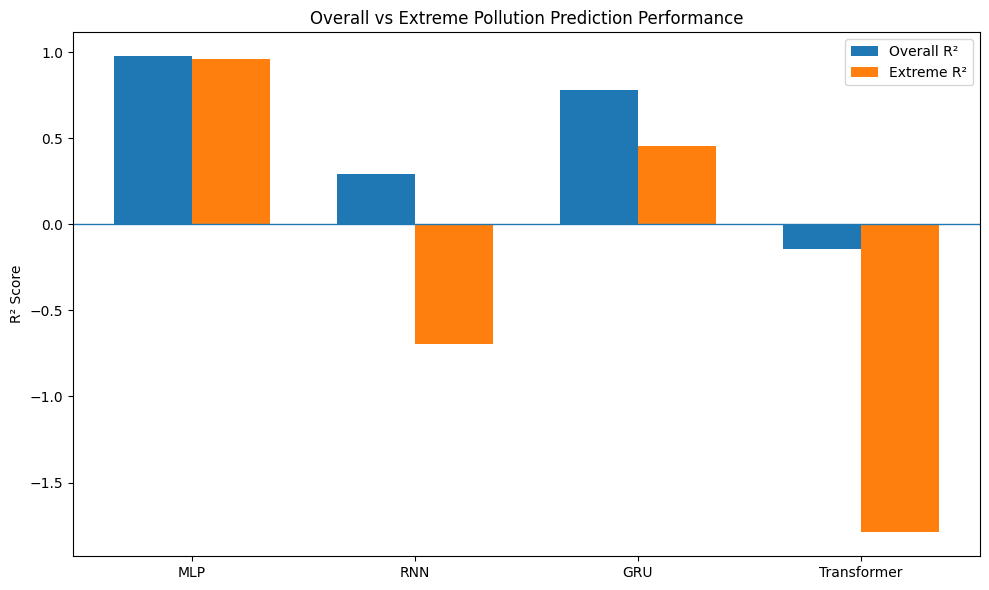

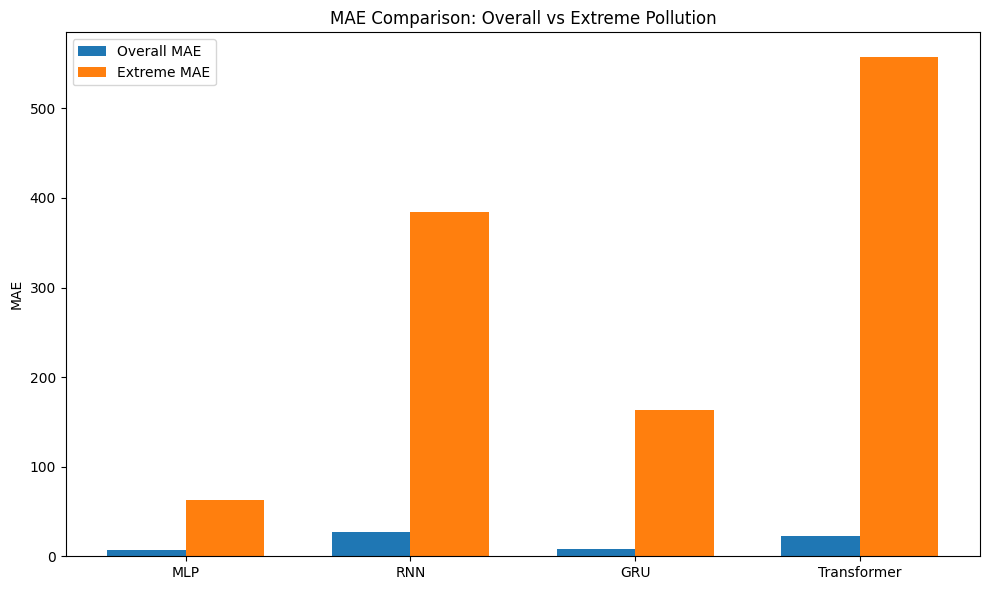

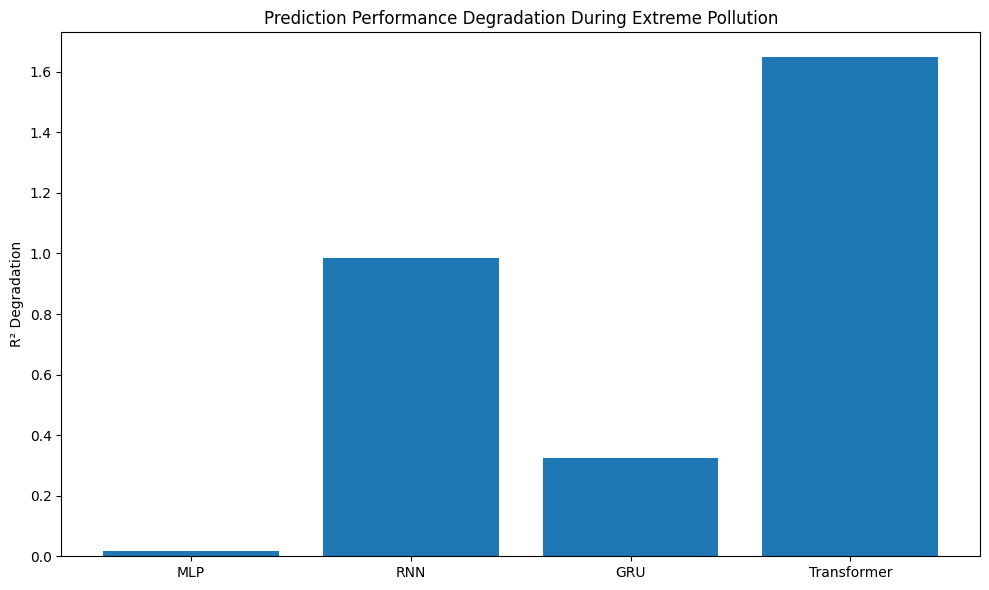


 COMPLETED SUCCESSFULLY.


In [33]:

# ============================================================
#  VISUALIZATION
# ============================================================

print("=" * 70)
print("STEP 32: MODEL PERFORMANCE VISUALIZATION")
print("=" * 70)

# 1. Overall and extreme R² comparison
plt.figure(figsize=(10, 6))

x = np.arange(len(model_comparison))
width = 0.35

plt.bar(
    x - width / 2,
    model_comparison["Overall R2"],
    width,
    label="Overall R²"
)

plt.bar(
    x + width / 2,
    model_comparison["Extreme R2"],
    width,
    label="Extreme R²"
)

plt.axhline(0, linewidth=1)
plt.xticks(x, model_comparison["Model"])
plt.ylabel("R² Score")
plt.title("Overall vs Extreme Pollution Prediction Performance")
plt.legend()
plt.tight_layout()
plt.show()


# 2. Overall and extreme MAE comparison
plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    model_comparison["Overall MAE"],
    width,
    label="Overall MAE"
)

plt.bar(
    x + width / 2,
    model_comparison["Extreme MAE"],
    width,
    label="Extreme MAE"
)

plt.xticks(x, model_comparison["Model"])
plt.ylabel("MAE")
plt.title("MAE Comparison: Overall vs Extreme Pollution")
plt.legend()
plt.tight_layout()
plt.show()


# 3. R² degradation comparison
plt.figure(figsize=(10, 6))

plt.bar(
    robustness_analysis["Model"],
    robustness_analysis["R2 Degradation"]
)

plt.ylabel("R² Degradation")
plt.title("Prediction Performance Degradation During Extreme Pollution")
plt.tight_layout()
plt.show()

print("\n COMPLETED SUCCESSFULLY.")


#  FINAL CONCLUSION

## Research Title

**When Air Quality Models Fail: Robustness of Machine Learning Predictions During Extreme Pollution Events in Indian Cities**

### 1. Research Objective

The objective of this study was to evaluate whether deep learning models maintain reliable air-quality predictions during extreme pollution episodes. Four architectures—Multi-Layer Perceptron (MLP), Recurrent Neural Network (RNN), Gated Recurrent Unit (GRU), and Transformer—were evaluated using the US_AQI target.

Extreme pollution was defined as **US_AQI ≥ 201**. The models were evaluated on a chronological test set, with a common parameter budget of 59,915 parameters per model.

### 2. Key Findings

- **MLP:** Achieved the strongest results in this experiment, with an overall R² of 0.9771 and an extreme-subset R² of 0.9593.
- **RNN:** Achieved an overall R² of 0.2926, which declined to −0.6933 during extreme pollution.
- **GRU:** Achieved an overall R² of 0.7804 and an extreme-subset R² of 0.4548.
- **Transformer:** Achieved an overall R² of −0.1419 and an extreme-subset R² of −1.7899.

The extreme-pollution subset contained 4,324 observations, representing 2.57% of the test samples.

### 3. Interpretation

The results show that prediction performance differed substantially across architectures. MLP performed best on both the overall test set and the extreme-pollution subset in this experiment. GRU also produced positive R² values in both evaluations, whereas RNN and Transformer produced negative R² values on the extreme subset.

These findings indicate that deep learning architectures do not necessarily provide equally reliable predictions during severe pollution conditions. However, the results do not establish that every model will fail during extreme events; performance depends on the architecture, data, and experimental setup.

### 4. Research Limitations

1. Extreme-pollution observations represented only 2.57% of the test set.
2. The models were evaluated on one chronological train-test split.
3. Equal parameter counts do not guarantee equal representational capacity or comparable optimization.
4. Additional validation is needed to confirm that the results remain stable across cities and time periods.
5. The unexpectedly strong MLP results should be checked with a persistence baseline, city-wise error analysis, and a leakage audit before drawing definitive conclusions.

### 5. Future Work

Future work should investigate additional chronological evaluation periods, city-specific performance, prediction errors across AQI severity levels, and alternative forecasting baselines. Further experiments should also examine whether targeted training or sampling strategies improve extreme-event prediction without compromising the validity of the evaluation.

### 6. Final Conclusion

In this experiment, MLP achieved the strongest overall and extreme-pollution prediction results among the four evaluated architectures. GRU showed moderate performance, while RNN and Transformer struggled, particularly on extreme-pollution observations.

The study highlights the importance of evaluating air-quality prediction models separately under ordinary and extreme conditions rather than relying only on overall performance metrics. Further validation is required before recommending any architecture for real-world air-quality warning systems.